# 02 · Who trades NFTs, and does their behaviour carry information?

**Data.** 2,382,584 OpenSea-style NFT sales (May 2021 → April 2025): buyer and seller wallets (anonymised), token, collection, USD price and timestamp. The dataset was provided for the course and is not redistributed (see `data/README.md`). **This notebook is therefore shown with the outputs of the original run**; code comments and printed labels were translated to English, while figure labels are still in French as rendered at the time.

**Questions**
1. How concentrated is activity across NFTs and across wallets (power law or log-normal)?
2. Can wallets be classified as *trend-followers*, *mean-reverters* or *neutral* from how their net inventory reacts to past returns?
3. Are these labels stable over time, and at which horizon do traders react?
4. Does anyone have skill: do directional trades earn money, does performance persist, and do aggregate flows predict market returns out of sample?

**Methods.** Polars (lazy group-bys on 2.4 M rows) · MLE power-law fits with likelihood-ratio tests (Clauset, Shalizi & Newman 2009, `powerlaw`) · per-wallet Pearson tests · transition matrices · directional PnL and Sharpe ratios · 50/50 out-of-sample split · linear and ridge regression.

**Results in one paragraph.** Activity is extremely concentrated (median wallet: 2 purchases; maximum: 32,602), with heavy tails that are clearly not exponential but cannot be told apart from a log-normal. About half of the 9,649 active wallets show a significant correlation between inventory changes and the previous day's return, split almost evenly between trend-following and mean-reverting. **None of the skill measures survives an out-of-sample test**: labels assigned in the first half of the sample are statistically independent of the labels in the second half, top-quintile traders stay top-quintile at the chance rate (19–25% vs 20%), and aggregate trader flows give a negative out-of-sample R² at every horizon. The limitations section explains why part of the in-sample signal may be mechanical.

## 0 · Setup and data loading

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import polars as pl
import powerlaw
import seaborn as sns
import json
from scipy import stats
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ── Shared colour palette ──────────
DARK  = '#0f1117'
CARD  = '#1a1d27'
BLUE  = '#378ADD'
TEAL  = '#1D9E75'
CORAL = '#D85A30'
AMBER = '#EF9F27'
LGRAY = '#8b8fa8'
WHITE = '#e8eaf0'

def style_ax(ax, title):
    """Uniform dark style for all axes."""
    ax.set_facecolor(CARD)
    ax.spines[:].set_color('#2a2d3e')
    ax.tick_params(colors=LGRAY, labelsize=9)
    ax.xaxis.label.set_color(LGRAY)
    ax.yaxis.label.set_color(LGRAY)
    ax.set_title(title, color=WHITE, fontsize=10, fontweight='bold', pad=8)
    ax.grid(True, color='#2a2d3e', linewidth=0.5, linestyle='--')

print("✓ Imports OK")

✓ Imports OK


In [2]:
# ── Load CSV and convert to Parquet ────────────────────
df = pl.read_csv("../data/sales.csv")
df.write_parquet("../data/sales.parquet")
df_parquet = pl.read_parquet("../data/sales.parquet")

print(f"Dimensions : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Colonnes   : {df.columns}")

Dimensions : 2,382,584 rows × 32 columns
Colonnes   : ['event_type', 'order_hash', 'chain', 'protocol_address', 'closing_date', 'nft_identifier', 'nft_collection', 'nft_contract', 'nft_token_standard', 'nft_name', 'nft_description', 'nft_image_url', 'nft_display_image_url', 'nft_display_animation_url', 'nft_metadata_url', 'nft_opensea_url', 'nft_updated_at', 'nft_is_disabled', 'nft_is_nsfw', 'quantity', 'seller', 'buyer', 'payment_quantity', 'payment_token_address', 'payment_decimals', 'payment_symbol', 'transaction', 'event_timestamp', 'eth_usd_price', 'avg_gas_price', 'payment_usd_price', 'log_usd_price']


---

## Section 1 — Transaction distribution by NFT

### Approach

We aggregate the number of transactions per NFT, identified by `nft_identifier`, and then plot the **CCDF (Complementary Cumulative Distribution Function)** on log-log axes.

The CCDF gives the probability $P(X \geq x)$. If the curve is approximately linear in log-log scale, the distribution may follow a **power law**, with $P(X \geq x) \sim x^{-\alpha+1}$. However, visual inspection can be misleading: log-normal and stretched-exponential distributions can also look nearly linear over part of the graph. This is why a formal fit and model comparison are needed.

We then fit a `powerlaw` model and compare the power-law model with the log-normal model using the **likelihood-ratio (LR) test** following Clauset et al. The LR test indicates which of the two models is more likely to have generated the observed data.

> **Mathematical context:** for a probability mass function $P(X=x) \propto x^{-\alpha}$, the corresponding CCDF decays roughly as $P(X \geq x) \propto x^{-(\alpha-1)}$. This is why the CCDF slope is related to, but not equal to, the power-law exponent $\alpha$.

In [ ]:
# ── Aggregation: number of transactions per NFT ───────────────
tx_per_nft = (
    df.group_by(["nft_identifier"])
      .len()
      .rename({"len": "n_transactions"})
)

print(f"Unique NFT identifiers : {tx_per_nft.shape[0]:,}")
print(tx_per_nft.head())

Unique NFT identifiers : 24,726
shape: (5, 2)
┌────────────────┬────────────────┐
│ nft_identifier ┆ n_transactions │
│ ---            ┆ ---            │
│ i64            ┆ u32            │
╞════════════════╪════════════════╡
│ 11442          ┆ 59             │
│ 18912          ┆ 12             │
│ 15360          ┆ 19             │
│ 3189           ┆ 205            │
│ 6303           ┆ 320            │
└────────────────┴────────────────┘


> **Caveat.** `nft_identifier` is a token number *within* a collection, so grouping on it alone merges, for example, token #689 of every collection. The figures below therefore describe activity per token number rather than per individual NFT; grouping on `(nft_collection, nft_identifier)` is the correct key (used in Section 3).

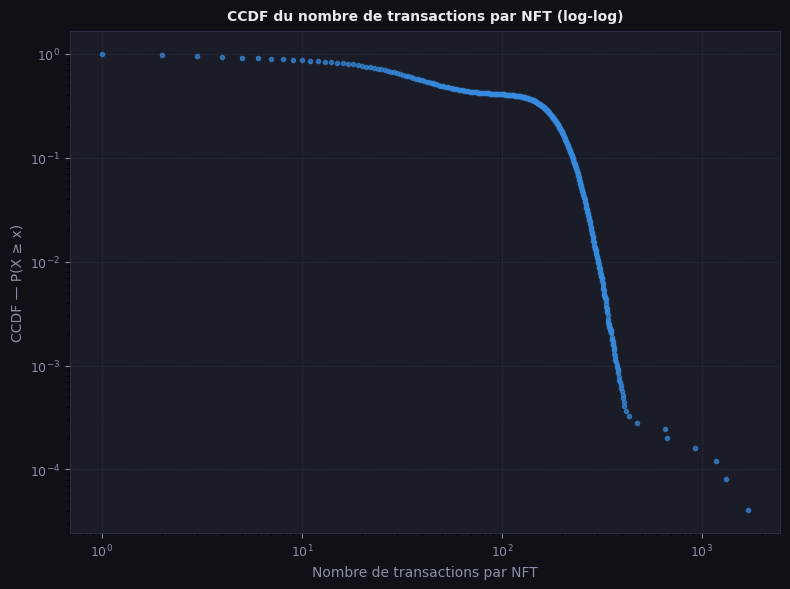

In [4]:
counts = tx_per_nft["n_transactions"].to_numpy()
x = np.sort(np.unique(counts))
ccdf = np.array([np.mean(counts >= k) for k in x])

# ── CCDF empirique (log-log) ───────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor(DARK)
ax.loglog(x, ccdf, marker='.', linestyle='none', color=BLUE, alpha=0.7)
ax.set_xlabel("Transactions per NFT")
ax.set_ylabel("CCDF — P(X ≥ x)")
style_ax(ax, "CCDF of transactions per NFT (log-log)")
plt.tight_layout()
plt.show()

In [5]:
# ── Power-law fit ───────────────────────────────────────
fit_nft = powerlaw.Fit(counts, discrete=True)
R_ln, p_ln = fit_nft.distribution_compare('power_law', 'lognormal')

print(f"α (MLE)  : {fit_nft.power_law.alpha:.4f}")
print(f"xmin      : {fit_nft.power_law.xmin}")
print(f"LR vs log-normal : R={R_ln:.3f}, p={p_ln:.3f}")
print()
if abs(R_ln) < 1 or p_ln > 0.1:
    print("→ Inconclusive: the power law cannot be statistically")
    print("  distinguished from the log-normal on this sample.")

Calculating best minimal value for power law fit


α (MLE)  : 2.9155
xmin      : 406.0
LR vs log-normal : R=-0.009, p=0.936

→ Inconclusive: the power law cannot be statistically
  distinguished from the log-normal on this sample.


**Reading.** α ≈ 2.92 above $x_{\min} = 406$, but the likelihood-ratio test against a log-normal is flat (R = −0.009, p = 0.94): the data cannot discriminate between a preferential-attachment story (power law) and the compounding of independent multiplicative shocks (log-normal). Only the top of the distribution (tokens with more than 406 trades) enters the fit, so the conclusion concerns the most active tokens only.

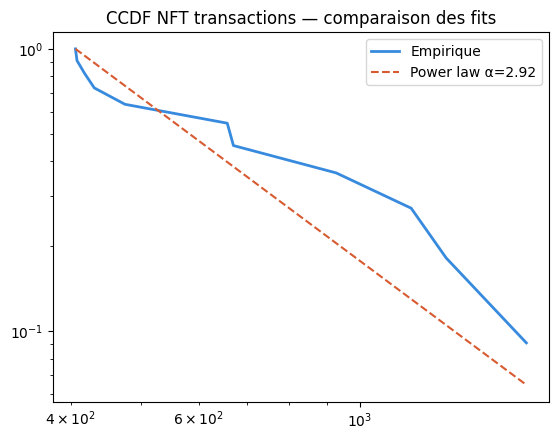

In [6]:
# ── CCDF: data vs fits ───────────────────────────
fig = fit_nft.plot_ccdf(color=BLUE, linewidth=2, label='Empirical')
fit_nft.power_law.plot_ccdf(ax=fig, color=CORAL, linestyle='--', label=f'Power law α={fit_nft.power_law.alpha:.2f}')
plt.legend()
plt.title("CCDF of NFT transactions — fit comparison", color='black')
plt.show()

---

## Section 2 — Distribution of purchases and sales by trader

### Approach

We filter transactions of type `sale` and compute, for each wallet:
- the number of **purchases** in the `buyer` role;
- the number of **sales** in the `seller` role.

We fit a power law to each distribution and visually compare the two profiles.

### Theoretical context — power laws

A distribution follows a power law when $P(X=x) \sim x^{-\alpha}$.  
The exponent **α** measures the heaviness of the tail:
- $\alpha \in [2,3]$: the mean is finite, while the variance can be very large or unstable depending on the exact definition and support. This is common in financial and activity distributions.
- $\alpha < 2$: extremes dominate even more strongly, and averages become highly sensitive to the largest observations.

In this setting, a heavy tail means that a small number of wallets can account for a disproportionate share of market activity.

In [7]:
# ── Distribution of purchases per trader ────────────────────────
buy_counts = (
    df.filter(pl.col("event_type") == "sale")
    .group_by("buyer")
    .agg(pl.len().alias("n_buys"))
    .sort("n_buys", descending=True)
)

print("Descriptive statistics — purchases per trader:")
print(buy_counts.describe())

Descriptive statistics — purchases per trader:
shape: (9, 3)
┌────────────┬──────────────────┬────────────┐
│ statistic  ┆ buyer            ┆ n_buys     │
│ ---        ┆ ---              ┆ ---        │
│ str        ┆ str              ┆ f64        │
╞════════════╪══════════════════╪════════════╡
│ count      ┆ 306253           ┆ 306253.0   │
│ null_count ┆ 0                ┆ 0.0        │
│ mean       ┆ null             ┆ 7.77979    │
│ std        ┆ null             ┆ 110.036968 │
│ min        ┆ 000024b759f765e5 ┆ 1.0        │
│ 25%        ┆ null             ┆ 1.0        │
│ 50%        ┆ null             ┆ 2.0        │
│ 75%        ┆ null             ┆ 4.0        │
│ max        ┆ ffffe404b26ffebe ┆ 32602.0    │
└────────────┴──────────────────┴────────────┘


**The distribution is extremely skewed.** Median 2 purchases, mean 7.8, standard deviation 110, maximum 32,602. Three quarters of the 306,253 buying wallets made 4 purchases or fewer; volume comes from a small group of very active wallets (bots, market makers, possibly wash traders).

In [8]:
def plot_trader_distribution(data_arr, label, color_main):
    """
    Six-panel diagnostic of a count distribution
    (purchases or sales per trader).
    """
    fit = powerlaw.Fit(data_arr, discrete=True, verbose=False)
    alpha_hat = fit.power_law.alpha
    xmin_hat  = fit.power_law.xmin
    sigma_hat = fit.power_law.sigma
    R_ln, p_ln   = fit.distribution_compare('power_law', 'lognormal')
    R_exp, p_exp = fit.distribution_compare('power_law', 'exponential')

    fig = plt.figure(figsize=(14, 10))
    fig.patch.set_facecolor(DARK)
    gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

    # 1. Linear histogram
    ax1 = fig.add_subplot(gs[0, 0])
    bins_edges = [1,2,3,4,5,8,12,20,40,80,150,500, data_arr.max()+1]
    counts_h, _ = np.histogram(data_arr, bins=bins_edges)
    labels_h = ['1','2','3','4','5','6-7','8-11','12-19','20-39','40-79','80-149','150+']
    ax1.bar(range(len(counts_h)), counts_h, color=color_main, alpha=0.85,
            edgecolor=DARK, linewidth=0.4)
    ax1.set_xticks(range(len(counts_h)))
    ax1.set_xticklabels(labels_h, rotation=45, ha='right', fontsize=7.5)
    ax1.set_ylabel("Number of traders", color=LGRAY)
    style_ax(ax1, "1. Linear histogram")

    # 2. PDF log-log + fits
    ax2 = fig.add_subplot(gs[0, 1])
    powerlaw.plot_pdf(data_arr, color=color_main, linewidth=1.5, label='Empirical', ax=ax2)
    fit.power_law.plot_pdf(color=CORAL, linestyle='--', linewidth=2,
                           label=f'Power law α={alpha_hat:.2f}', ax=ax2)
    fit.lognormal.plot_pdf(color=TEAL, linestyle=':', linewidth=1.8, label='Log-normal', ax=ax2)
    ax2.set_xlabel("Count (log)"); ax2.set_ylabel("PDF (log)")
    ax2.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
    style_ax(ax2, "2. PDF log-log + fits")

    # 3. CCDF log-log + fits
    ax3 = fig.add_subplot(gs[0, 2])
    powerlaw.plot_ccdf(data_arr, color=color_main, linewidth=1.5, label='Empirical CCDF', ax=ax3)
    fit.power_law.plot_ccdf(color=CORAL, linestyle='--', linewidth=2,
                            label=f'Power law α={alpha_hat:.2f}', ax=ax3)
    fit.lognormal.plot_ccdf(color=TEAL, linestyle=':', linewidth=1.8, label='Log-normal', ax=ax3)
    ax3.set_xlabel("Count (log)"); ax3.set_ylabel("P(X ≥ x) [log]")
    ax3.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
    style_ax(ax3, "3. CCDF log-log + fits")

    # 4. Rank-frequency (Zipf)
    ax4 = fig.add_subplot(gs[1, 0])
    sorted_desc = np.sort(data_arr)[::-1]
    ranks = np.arange(1, len(sorted_desc)+1)
    ax4.loglog(ranks, sorted_desc, '.', color=color_main, alpha=0.25, markersize=2)
    x_r = np.logspace(np.log10(1), np.log10(ranks[-1]), 300)
    ax4.loglog(x_r, sorted_desc[0] * x_r**(-1/(alpha_hat-1)),
               color=CORAL, linewidth=2, linestyle='--', label=f'Theoretical slope α={alpha_hat:.2f}')
    ax4.set_xlabel("Rank (log)"); ax4.set_ylabel("Count (log)")
    ax4.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
    style_ax(ax4, "4. Rank-frequency (Zipf)")

    # 5. Violin plot (capped at p99)
    ax5 = fig.add_subplot(gs[1, 1])
    capped = np.clip(data_arr, 1, np.percentile(data_arr, 99))
    parts = ax5.violinplot(capped, positions=[1], showmedians=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color_main); pc.set_alpha(0.5)
    parts['cmedians'].set_color(AMBER); parts['cmedians'].set_linewidth(2)
    for k in ('cmaxes','cmins','cbars'): parts[k].set_color(LGRAY)
    m, med = data_arr.mean(), np.median(data_arr)
    ax5.axhline(m, color=CORAL, linewidth=1.2, linestyle='--', label=f'Mean={m:.1f}')
    ax5.axhline(med, color=TEAL, linewidth=1.2, linestyle=':', label=f'Median={med:.0f}')
    ax5.set_xticks([1]); ax5.set_xticklabels(['traders'])
    ax5.set_ylabel("Count (capped p99)"); ax5.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
    style_ax(ax5, "5. Violin plot (cap. p99)")

    # 6. Summary table
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.set_facecolor(CARD); ax6.axis('off')
    rows = [
        ("Unique traders",      f"{len(data_arr):,}"),
        ("Min / Max",            f"{int(data_arr.min())} / {int(data_arr.max())}"),
        ("Median",              f"{np.median(data_arr):.0f}"),
        ("Mean",              f"{data_arr.mean():.2f}"),
        ("Std",                  f"{data_arr.std():.2f}"),
        ("Skewness",             f"{float(pl.Series(data_arr).skew()):.2f}"),
        ("", ""),
        ("α (MLE)",       f"{alpha_hat:.4f}"),
        ("σ(α)",                 f"{sigma_hat:.4f}"),
        ("xmin",                 f"{int(xmin_hat)}"),
        ("", ""),
        ("LR pw vs lognormal",  f"R={R_ln:.3f}  p={p_ln:.3f}"),
        ("LR pw vs exponential", f"R={R_exp:.3f}  p={p_exp:.3f}"),
        ("Best fit",         "power law" if R_ln > 0 else "log-normal"),
    ]
    for i, (k, v) in enumerate(rows):
        if k == "": continue
        c_k = AMBER if k.startswith("α") or k.startswith("LR") or k=="Best fit" else LGRAY
        ax6.text(0.05, 1 - i*0.072, k, transform=ax6.transAxes, fontsize=8.5, color=c_k, va='top')
        ax6.text(0.98, 1 - i*0.072, v, transform=ax6.transAxes, fontsize=8.5, color=WHITE,
                 va='top', ha='right', fontweight='bold')
    ax6.set_title("Statistics & fit", color=WHITE, fontsize=10, fontweight='bold', pad=8)

    fig.suptitle(f"Number of {label} per trader — NFT",
                 color=WHITE, fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()
    return fit, alpha_hat, xmin_hat, sigma_hat, R_ln, p_ln, R_exp, p_exp

print("✓ plot_trader_distribution defined")

✓ plot_trader_distribution defined


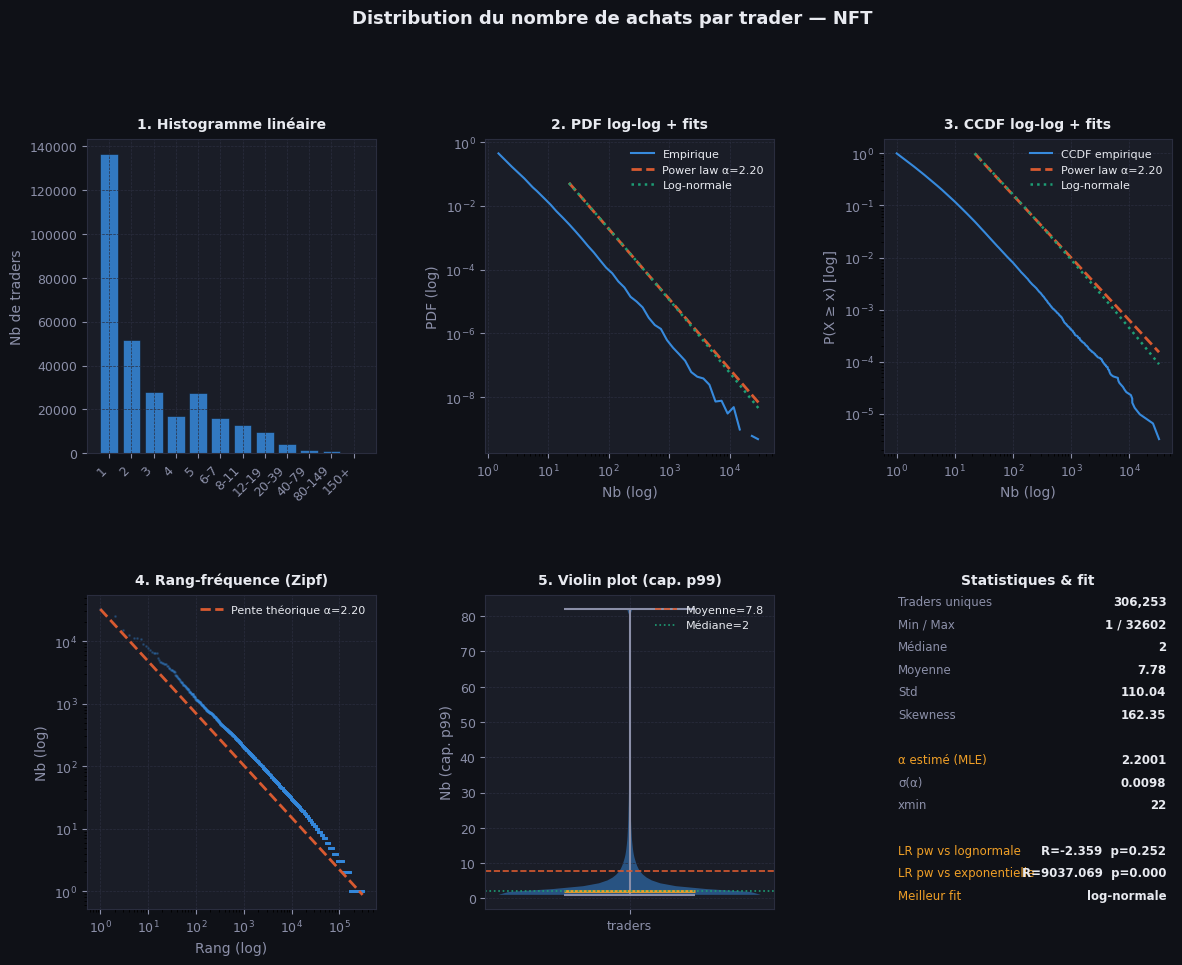

In [9]:
# ── Distribution of PURCHASES ─────────────────────
buy_data = buy_counts["n_buys"].to_numpy().astype(float)
fit_buy, alpha_buy, xmin_buy, sigma_buy, R_ln_buy, p_ln_buy, R_exp_buy, p_exp_buy = \
    plot_trader_distribution(buy_data, "purchases", BLUE)

| Indicator | Purchases | Reading |
|---|---|---|
| α (MLE) | ≈ 2.20, σ(α) ≈ 0.010 | heavy tail in the usual range for activity data |
| $x_{\min}$ | 22 | the power-law regime only covers wallets with 22+ purchases |
| LR vs exponential | R ≫ 0, p ≈ 0 | exponential clearly rejected |
| LR vs log-normal | R < 0, p > 0.05 | not significant: log-normal is as good |

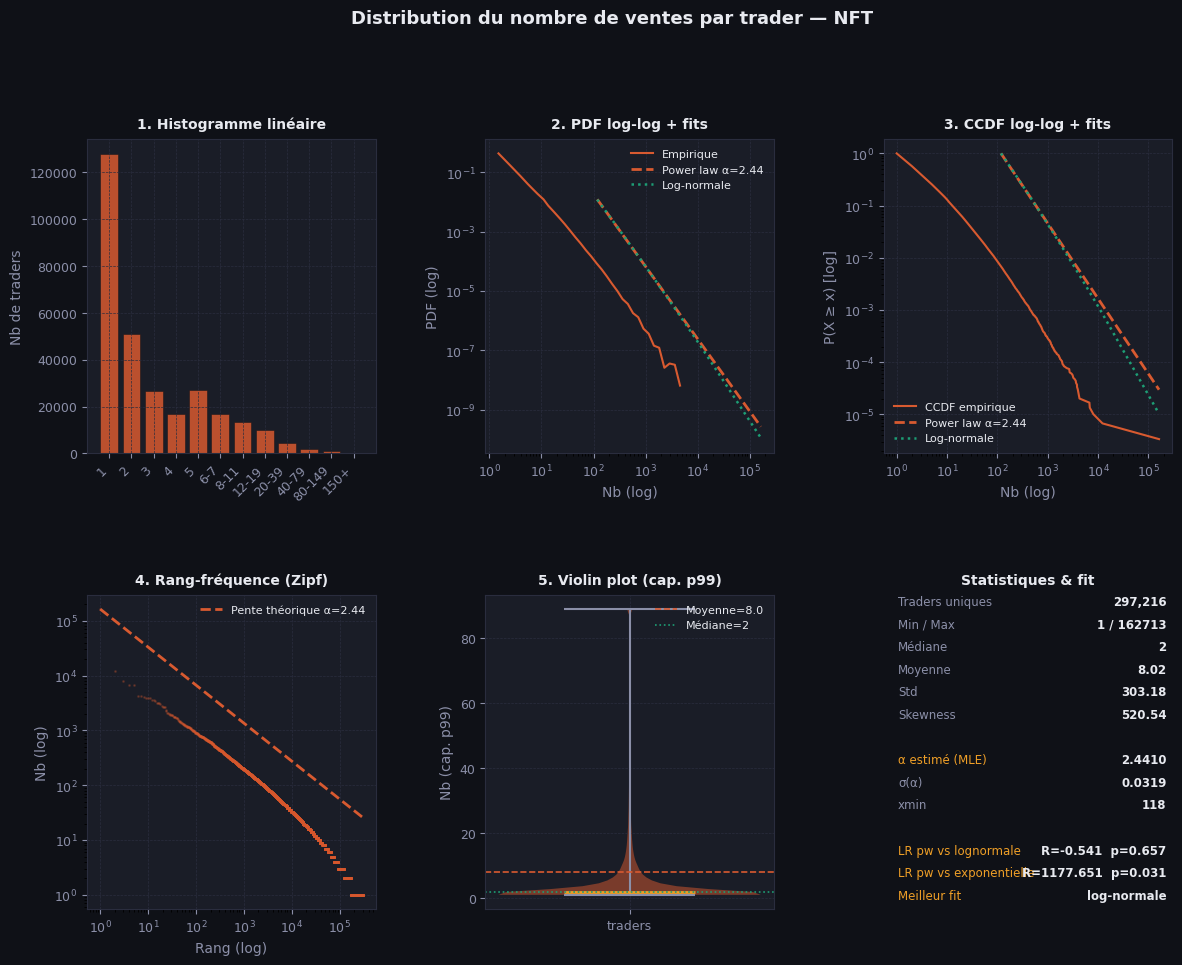

In [10]:
# ── Distribution of SALES ─────────────────────
sell_counts = (
    df.filter(pl.col("event_type") == "sale")
    .group_by("seller")
    .agg(pl.len().alias("n_sells"))
    .sort("n_sells", descending=True)
)
sell_data = sell_counts["n_sells"].to_numpy().astype(float)
fit_sell, alpha_sell, xmin_sell, sigma_sell, R_ln_sell, p_ln_sell, R_exp_sell, p_exp_sell = \
    plot_trader_distribution(sell_data, "sales", CORAL)

Sales look the same: α ≈ 2.20, exponential rejected, power law vs log-normal undecided (p ≈ 0.84). The tail starts earlier ($x_{\min}$ = 10 vs 22), i.e. there are relatively more very active sellers than very active buyers.

---

## Section 3 — Analysis of the most traded asset

### Approach

We identify the NFT with the largest number of `sale` transactions and then analyze the **distribution of its daily transaction count**. This tests whether trading concentration around a single asset also follows a heavy-tailed law.

We also analyze the **Meebits** collection by comparing purchase and sale distributions.

In [11]:
# ── Most traded NFT ───────────────────────
top = (
    df.filter(pl.col("event_type") == "sale")
    .group_by("nft_collection", "nft_identifier", "nft_name")
    .agg(pl.len().alias("n_trades"))
    .sort("n_trades", descending=True)
    .row(0, named=True)
)

print(f"Most traded NFT  : {top['nft_name']}  ({top['nft_identifier']})")
print(f"Collection         : {top['nft_collection']}")
print(f"Number of trades   : {top['n_trades']}")

Most traded NFT  : Meebit #689  (689)
Collection         : meebits
Number of trades   : 1491


In [12]:
# ── Daily series for this asset ───────────────
asset_df = df.filter(
    (pl.col("event_type") == "sale") &
    (pl.col("nft_identifier") == top["nft_identifier"]) &
    (pl.col("nft_collection") == top["nft_collection"])
)

daily = (
    asset_df
    .with_columns(
        pl.col("event_timestamp")
        .str.to_datetime(format="%Y-%m-%d %H:%M:%S", strict=False)
        .dt.date()
        .alias("date")
    )
    .group_by("date")
    .agg(pl.len().alias("n_tx"))
    .sort("date")
)

daily_data = daily["n_tx"].to_numpy().astype(float)

# Fit powerlaw
fit_daily = powerlaw.Fit(daily_data, discrete=True, verbose=False)
R_ln_d, p_ln_d   = fit_daily.distribution_compare('power_law', 'lognormal')
R_exp_d, p_exp_d = fit_daily.distribution_compare('power_law', 'exponential')

print(f"α  : {fit_daily.power_law.alpha:.4f}   σ : {fit_daily.power_law.sigma:.4f}   xmin : {int(fit_daily.power_law.xmin)}")
print(f"LR vs lognormal     : R={R_ln_d:.3f}  p={p_ln_d:.3f}")
print(f"LR vs exponential   : R={R_exp_d:.3f}  p={p_exp_d:.3f}")

α  : 1.9593   σ : 0.0736   xmin : 3
LR vs lognormal     : R=-39.732  p=0.000
LR vs exponential   : R=-41.402  p=0.000


**Reading.** This is the distribution of the **number of trades per day** for Meebit #689 (1,491 trades in total). Both likelihood-ratio tests reject the power law decisively (R ≈ −40, p < 0.001) in favour of the log-normal and the exponential: the daily activity of the most traded token has a thin tail, with bursts bounded at about 15–20 trades a day rather than occasional extreme spikes.

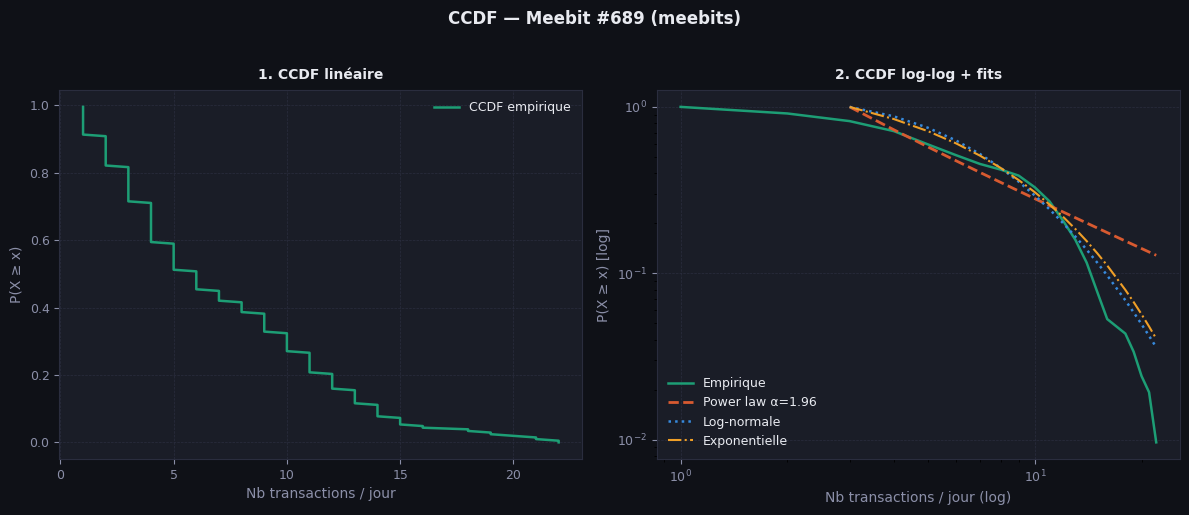

In [13]:
# ── CCDF — most traded asset ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(DARK)
fig.suptitle(f"CCDF — {top['nft_name']} ({top['nft_collection']})",
             color=WHITE, fontsize=12, fontweight='bold', y=1.02)

# Linear CCDF
ax1 = axes[0]
s = np.sort(daily_data)
ccdf_d = 1 - np.arange(1, len(s)+1) / len(s)
ax1.plot(s, ccdf_d, color=TEAL, linewidth=1.8, label='Empirical CCDF')
ax1.set_xlabel("Transactions per day"); ax1.set_ylabel("P(X ≥ x)")
ax1.legend(fontsize=9, framealpha=0, labelcolor=WHITE)
style_ax(ax1, "1. Linear CCDF")

# CCDF log-log
ax2 = axes[1]
powerlaw.plot_ccdf(daily_data, color=TEAL, linewidth=1.8, label='Empirical', ax=ax2)
fit_daily.power_law.plot_ccdf(color=CORAL, linestyle='--', linewidth=2,
                              label=f'Power law α={fit_daily.power_law.alpha:.2f}', ax=ax2)
fit_daily.lognormal.plot_ccdf(color=BLUE, linestyle=':', linewidth=1.8, label='Log-normal', ax=ax2)
fit_daily.exponential.plot_ccdf(color=AMBER, linestyle='-.', linewidth=1.5, label='Exponential', ax=ax2)
ax2.set_xlabel("Transactions per day (log)"); ax2.set_ylabel("P(X ≥ x) [log]")
ax2.legend(fontsize=9, framealpha=0, labelcolor=WHITE)
style_ax(ax2, "2. CCDF log-log + fits")

plt.tight_layout()
plt.show()

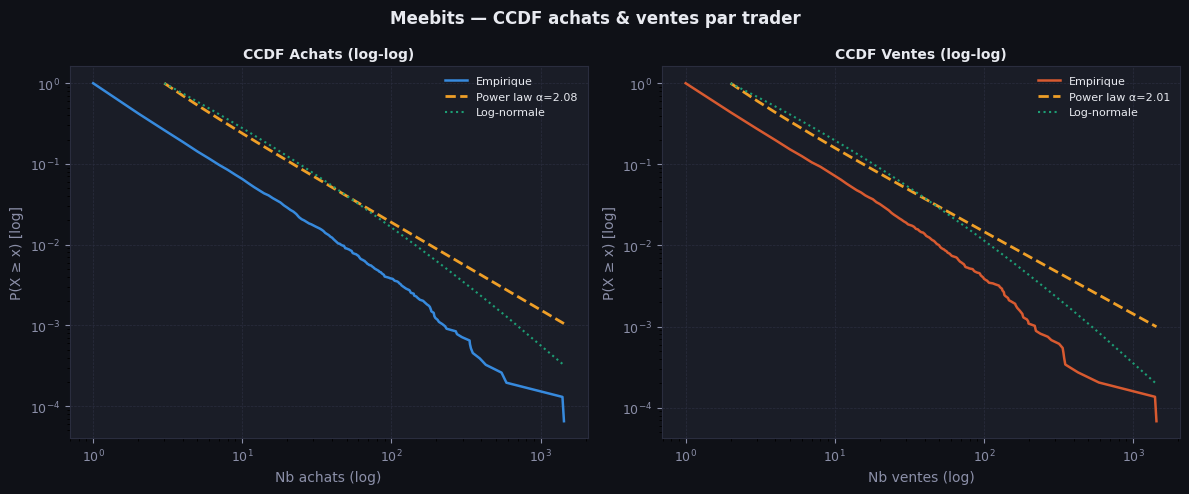

In [14]:
# ── Meebits collection — purchases vs sales ─────────────────────
meebit = df.filter(
    (pl.col("event_type") == "sale") &
    (pl.col("nft_collection") == "meebits")
)

meebit_buy  = meebit.group_by("buyer").agg(pl.len().alias("n_buys"))["n_buys"].to_numpy().astype(float)
meebit_sell = meebit.group_by("seller").agg(pl.len().alias("n_sells"))["n_sells"].to_numpy().astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(DARK)
fig.suptitle("Meebits — CCDF of purchases & sales per trader", color=WHITE, fontsize=12, fontweight='bold')

for ax, data, label, color in [
    (axes[0], meebit_buy,  "Purchases",  BLUE),
    (axes[1], meebit_sell, "Sales", CORAL),
]:
    fit = powerlaw.Fit(data, discrete=True, verbose=False)
    powerlaw.plot_ccdf(data, color=color, linewidth=1.8, label='Empirical', ax=ax)
    fit.power_law.plot_ccdf(color=AMBER, linestyle='--', linewidth=2,
                            label=f'Power law α={fit.power_law.alpha:.2f}', ax=ax)
    fit.lognormal.plot_ccdf(color=TEAL, linestyle=':', linewidth=1.5, label='Log-normal', ax=ax)
    ax.set_facecolor(CARD); ax.spines[:].set_color('#2a2d3e')
    ax.tick_params(colors=LGRAY, labelsize=9)
    ax.xaxis.label.set_color(LGRAY); ax.yaxis.label.set_color(LGRAY)
    ax.set_title(f"CCDF {label} (log-log)", color=WHITE, fontsize=10, fontweight='bold')
    ax.set_xlabel(f"{label} (log)"); ax.set_ylabel("P(X ≥ x) [log]")
    ax.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
    ax.grid(True, color='#2a2d3e', linewidth=0.5, linestyle='--')

plt.tight_layout()
plt.show()

Within the Meebits collection, buy and sell counts per wallet are almost symmetric (α ≈ 2.08 and 2.01). The empirical CCDFs bend below the fitted power law in the far tail: fewer extreme wallets than a pure power law would predict.

---

## Section 4 — Choice of time aggregation interval

### Approach

Before analyzing trader behavior over time, we need to choose an appropriate **time aggregation interval**. We compare four granularities:

| Interval | Advantages | Drawbacks |
|----------|------------|-----------|
| **Minute** | Maximum resolution; captures micro-dynamics | Very sparse: most minutes have 0 transactions; extremely noisy |
| **Hour** | Captures intraday dynamics | Still noisy; strong microstructure noise |
| **Day** | Good signal/noise balance; median above 1,000 transactions/day | Hides intraday dynamics |
| **Week** | Smooths noise | Loses short-term dynamics; too few observations (~209) |

We also examine the **distribution of inter-transaction times** to understand whether the order flow is continuous or clustered.

> **Mathematical context:** the aggregation interval controls a bias-variance tradeoff. Short intervals preserve more information but create sparse and noisy series; longer intervals reduce noise but may erase short-term dynamics.

In [15]:
# ── Choice of time granularity ──────────────────
df_sales = df.filter(pl.col("event_type") == "sale").with_columns(
    pl.col("event_timestamp")
    .str.to_datetime(format="%Y-%m-%d %H:%M:%S", strict=False)
    .alias("dt")
)

t_min, t_max = df_sales["dt"].min(), df_sales["dt"].max()
n_tx = len(df_sales)
print(f"First transaction    : {t_min}")
print(f"Last transaction     : {t_max}")
print(f"Total span           : {(t_max - t_min).days} days")
print(f"Total transactions   : {n_tx:,}")

First transaction    : 2021-05-01 00:15:48
Last transaction     : 2025-04-30 22:59:23
Total span           : 1460 days
Total transactions   : 2,382,584


In [16]:
# ── Statistics by granularity ──────────────────────────────
daily_tx = (
    df_sales
    .with_columns(pl.col("dt").dt.date().alias("date"))
    .group_by("date")
    .agg(pl.len().alias("n_tx"))
    .sort("date")
)

hourly_tx = (
    df_sales
    .with_columns(pl.col("dt").dt.truncate("1h").alias("hour"))
    .group_by("hour")
    .agg(pl.len().alias("n_tx"))
    .sort("hour")
)

gaps = df_sales.sort("dt")["dt"].diff().drop_nulls().dt.total_minutes()

print("=== DAILY granularity ===")
print(f"Tx/day median   : {daily_tx['n_tx'].median():.0f}")
print(f"Tx/day mean     : {daily_tx['n_tx'].mean():.1f}")
print(f"Tx/day max      : {daily_tx['n_tx'].max()}")
print(f"Active days     : {len(daily_tx)}")

print("\n=== HOURLY granularity ===")
print(f"Tx/hour median   : {hourly_tx['n_tx'].median():.0f}")
print(f"Tx/hour max      : {hourly_tx['n_tx'].max()}")

print("\n=== Time between transactions (minutes) ===")
print(f"Median : {gaps.median():.1f}  |  p95 : {gaps.quantile(0.95):.1f}")
print("\n→ Median gap = 0 min → near-continuous flow")
print("→ Decision: DAILY step (median price per day, ~1460 points)")

=== DAILY granularity ===
Tx/day median   : 1240
Tx/day mean     : 1629.7
Tx/day max      : 92873
Active days     : 1462

=== HOURLY granularity ===
Tx/hour median   : 45
Tx/hour max      : 92873

=== Time between transactions (minutes) ===
Median : 0.0  |  p95 : 3.0

→ Median gap = 0 min → near-continuous flow
→ Decision: DAILY step (median price per day, ~1460 points)


**Data-quality note.** The daily and hourly maxima are both exactly **92,873**, which is the number of rows whose timestamp fails to parse (`strict=False` returns null). Those rows end up in a single null bucket; they are dropped by the inner joins later on, but they distort these summary counts (the 1,462 "active days" include that bucket). Notebook 03 drops them explicitly.

The median gap between consecutive sales is 0 minutes, so the market is effectively continuous; **daily** aggregation is kept as the working frequency.

---

## Section 5 — Investor classification

### Approach

Each trader is classified using the **Pearson correlation** between their **daily inventory change** ($\Delta\text{inventory} = \text{purchases} - \text{sales}$) and the **previous-day log return** of the global market.

#### Pearson test

For each trader $i$, we compute:

$$r_i = \frac{\displaystyle\sum_{t}\bigl(\Delta\text{inv}_{i,t} - \overline{\Delta\text{inv}_i}\bigr)\bigl(r_{t-1} - \bar{r}\bigr)}{\sqrt{\displaystyle\sum_{t}\bigl(\Delta\text{inv}_{i,t} - \overline{\Delta\text{inv}_i}\bigr)^2}\;\sqrt{\displaystyle\sum_{t}\bigl(r_{t-1} - \bar{r}\bigr)^2}}$$

The coefficient $r_i$ measures the **strength and direction** of the linear relationship between a trader's behavior and the market's past return. Its statistical significance is then tested using:

$$t_i = r_i\sqrt{\frac{n_i - 2}{1 - r_i^2}} \quad \sim \; t(n_i - 2)$$

This gives a **p-value**. If $p < 0.05$, the correlation is statistically significant: the trader's directional behavior is unlikely to be due to random noise alone.

#### Classification rule

We keep only traders with:
- at least **30 observations**, to make the Pearson test reasonably reliable;
- a **p-value < 0.05**, indicating significant correlation.

| Category | Condition | Interpretation |
|----------|-----------|----------------|
| **Trend-follower** | $r > 0$ and $p < 0.05$ | Buys after price increases and sells after price decreases — follows the trend |
| **Mean-reverter** | $r < 0$ and $p < 0.05$ | Buys after price decreases and sells after price increases — bets on mean reversion |
| **Neutral** | $p \geq 0.05$ | No significant relationship with past market returns |

> **Why Pearson + p-value rather than an arbitrary threshold such as ±0.1?** A fixed threshold on $r$ ignores sample size. A trader with $r = 0.08$ over 500 days may have a highly significant behavior ($p \ll 0.05$), while a trader with $r = 0.3$ over 35 days may not be statistically significant ($p > 0.05$). The statistical test accounts for both the strength of the relationship **and** the amount of data available.

#### Inventory autocorrelation

We also compute the **lag-1 Pearson autocorrelation** of the series $\Delta\text{inv}_{i,t}$:

$$\rho_i = \text{corr}\bigl(\Delta\text{inv}_{i,t},\; \Delta\text{inv}_{i,t-1}\bigr)$$

with its associated p-value. This measures the **persistence** of behavior:
- significant $\rho > 0$ → the trader has a **persistent** style: if they buy today, they tend to buy again tomorrow;
- significant $\rho < 0$ → the trader **alternates**: buying then selling, which is consistent with a market-making style;
- non-significant $\rho$ → behavior is **erratic** or opportunistic.

> Combining the two axes — **direction** (trend-following/mean-reverting/neutral) × **persistence** (persistent/alternating/erratic) — gives a more detailed behavioral classification for each trader.

In [ ]:
# ── Daily median price ────────────────────
daily_price = (
    df_sales
    .with_columns(pl.col("dt").dt.date().alias("date"))
    .group_by("date")
    .agg(pl.col("payment_usd_price").median().alias("price_med"))
    .sort("date")
    .with_columns(
        (pl.col("price_med") / pl.col("price_med").shift(1)).log().alias("return_t")
    )
    .drop_nulls()
)

print(f"Price series : {len(daily_price)} days")

Price series : 1461 days


In [ ]:
# ── Daily inventory change per trader ─────────────
buys = (
    df_sales
    .with_columns(pl.col("dt").dt.date().alias("date"))
    .group_by("buyer", "date")
    .agg(pl.len().alias("n_buys"))
)

sells = (
    df_sales
    .with_columns(pl.col("dt").dt.date().alias("date"))
    .group_by("seller", "date")
    .agg(pl.len().alias("n_sells"))
)

inventory = (
    buys.rename({"buyer": "trader"})
    .join(sells.rename({"seller": "trader"}), on=["trader", "date"], how="full")
    .with_columns([
        pl.col("trader").fill_null(pl.col("trader_right")),
        pl.col("date").fill_null(pl.col("date_right")),
        pl.col("n_buys").fill_null(0),
        pl.col("n_sells").fill_null(0),
    ])
    .drop(["trader_right", "date_right"])
    .with_columns(
        (pl.col("n_buys") - pl.col("n_sells")).alias("delta_inventory")
    )
)

# Join with the previous day's return (return_prev = r_{t-1})
returns_shifted = (
    daily_price
    .with_columns(pl.col("date").shift(-1).alias("date_next"))
    .select(["date_next", "return_t"])
    .rename({"date_next": "date", "return_t": "return_prev"})
    .drop_nulls()
)

inventory_with_returns = inventory.join(returns_shifted, on="date", how="inner")
print(f"Inventory × returns dataset : {inventory_with_returns.shape}")

Inventory × returns dataset : (2006700, 6)


In [ ]:
# ── Trader classification (Pearson r + p-value) ───────


MIN_OBS = 30
ALPHA   = 0.05

# Manual group-by because scipy's pearsonr is not available in Polars
grouped = inventory_with_returns.group_by("trader").agg([
    pl.col("delta_inventory"),
    pl.col("return_prev"),
    pl.len().alias("n_obs")
]).filter(pl.col("n_obs") >= MIN_OBS)

records = []
for row in grouped.iter_rows(named=True):
    di = np.array(row["delta_inventory"], dtype=float)
    rp = np.array(row["return_prev"], dtype=float)
    # Pearson test: coefficient r and p-value
    r, p = pearsonr(di, rp)
    records.append({
        "trader": row["trader"],
        "n_obs":  row["n_obs"],
        "corr":   r,
        "pvalue": p,
    })

trader_corr = pl.DataFrame(records)

# Classification based on SIGNIFICANCE (p < 0.05), not on an arbitrary threshold on r
trader_corr = trader_corr.with_columns(
    pl.when((pl.col("pvalue") < ALPHA) & (pl.col("corr") > 0))
      .then(pl.lit("trend-following"))
    .when((pl.col("pvalue") < ALPHA) & (pl.col("corr") < 0))
      .then(pl.lit("mean-reverting"))
    .otherwise(pl.lit("neutral"))
    .alias("investor_type")
).sort("corr")

summary = (
    trader_corr
    .group_by("investor_type")
    .agg([
        pl.len().alias("n_traders"),
        pl.col("corr").mean().alias("corr_mean"),
        pl.col("corr").std().alias("corr_std"),
        pl.col("pvalue").median().alias("pvalue_median"),
    ])
    .sort("investor_type")
)

total = len(trader_corr)
print(f"Traders classified : {total:,}")
print(summary)

# p-value summary by category
for t in ["trend-following", "mean-reverting", "neutral"]:
    sub = trader_corr.filter(pl.col("investor_type") == t)
    pvals = sub["pvalue"].to_numpy()
    print(f"\n{t}: n={len(sub)}, corr_mean={sub['corr'].mean():.4f}, "
          f"p_median={np.median(pvals):.4f}, p<0.01={np.mean(pvals<0.01)*100:.1f}%")

Traders classified : 9,649
shape: (3, 4)
┌─────────────────┬───────────┬───────────┬──────────┐
│ investor_type   ┆ n_traders ┆ corr_mean ┆ corr_std │
│ ---             ┆ ---       ┆ ---       ┆ ---      │
│ str             ┆ u32       ┆ f64       ┆ f64      │
╞═════════════════╪═══════════╪═══════════╪══════════╡
│ mean-reverting  ┆ 2251      ┆ -0.191899 ┆ 0.074538 │
│ neutral         ┆ 5044      ┆ 0.001073  ┆ 0.056042 │
│ trend-following ┆ 2354      ┆ 0.189949  ┆ 0.077241 │
└─────────────────┴───────────┴───────────┴──────────┘


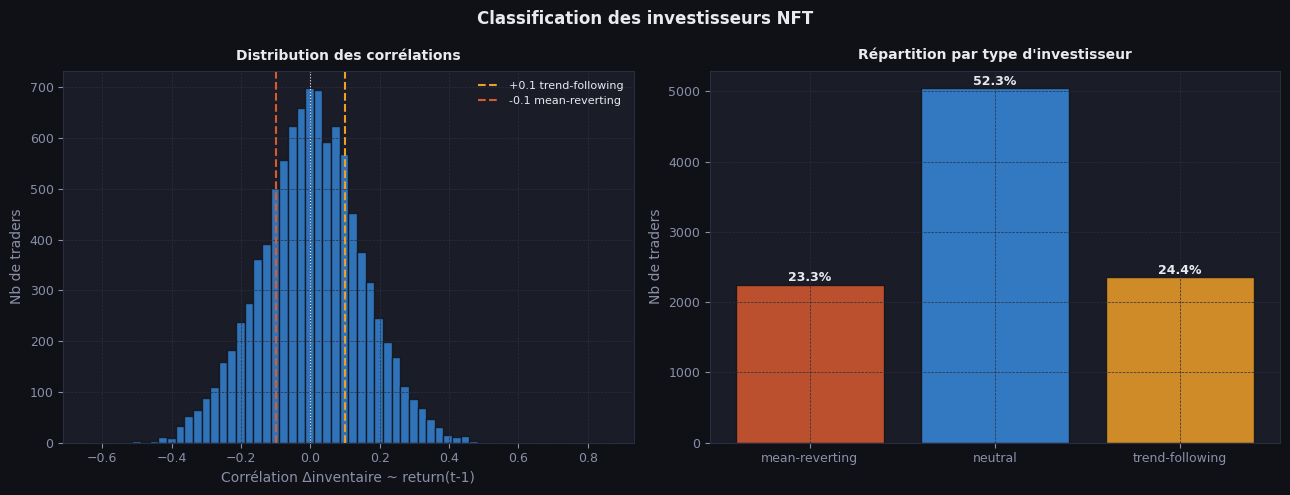

In [ ]:
# ── Classification plots (Pearson + p-value) ──
colors_map = {
    "trend-following": AMBER,
    "neutral":         BLUE,
    "mean-reverting":  CORAL,
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.patch.set_facecolor(DARK)

# 1. Distribution of correlations by type
ax1 = axes[0]
for inv_type, color in colors_map.items():
    sub = trader_corr.filter(pl.col("investor_type") == inv_type)["corr"].to_numpy()
    ax1.hist(sub, bins=40, color=color, alpha=0.6, edgecolor=DARK, label=inv_type)
ax1.axvline(0, color=WHITE, linewidth=0.8, linestyle=':')
ax1.set_xlabel("Correlation Δinventory ~ return(t-1)")
ax1.set_ylabel("Number of traders")
ax1.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
style_ax(ax1, "Distribution of correlations (by type)")

# 2. Distribution of p-values (log)
ax2 = axes[1]
pvals = trader_corr["pvalue"].to_numpy()
ax2.hist(pvals, bins=50, color=TEAL, alpha=0.8, edgecolor=DARK)
ax2.axvline(ALPHA, color=CORAL, linewidth=1.5, linestyle='--', label=f'threshold p={ALPHA}')
ax2.set_xlabel("p-value")
ax2.set_ylabel("Number of traders")
ax2.set_yscale("log")
ax2.legend(fontsize=8, framealpha=0, labelcolor=WHITE)
style_ax(ax2, "Distribution of p-values (Pearson)")

# 3. Breakdown by type
ax3 = axes[2]
type_counts = summary.sort("investor_type")
labels = type_counts["investor_type"].to_list()
counts_s = type_counts["n_traders"].to_list()
colors_s = [colors_map[l] for l in labels]
bars = ax3.bar(labels, counts_s, color=colors_s, alpha=0.85, edgecolor=DARK)
for bar, count in zip(bars, counts_s):
    pct = count / total * 100
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + total*0.005,
             f'{pct:.1f}%', ha='center', color=WHITE, fontsize=9, fontweight='bold')
ax3.set_ylabel("Number of traders")
style_ax(ax3, "Breakdown by investor type")

fig.suptitle("NFT investor classification (Pearson test, p < 0.05)",
             color=WHITE, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

*Note: the saved figure above was produced by an earlier version of this cell (two panels, with reference lines at r = ±0.1); the counts and shares it shows are identical to the table printed by the current code.*

### Results: classification

Among the **9,649 wallets** with at least 30 active days:

| Type | Count | Share | Mean correlation |
|---|---|---|---|
| Neutral (p ≥ 0.05) | 5,044 | 52% | 0.00 |
| Trend-following | 2,354 | 24% | +0.19 |
| Mean-reverting | 2,251 | 23% | −0.19 |

Under the null of no relation, 5% of wallets would be flagged by chance (≈ 480), so 48% significant is far more than noise alone. The near-perfect symmetry between the two directional groups, together with Section 6, suggests caution before reading this as a population of genuine strategies (see *Limitations*).

---

## Section 6 — Temporal stability of behavior

### Approach

We split the sample into **two equal time periods** and classify traders independently in each sub-period. We then build the **transition matrix**: among traders classified as one type in period 1, what fraction ends up in each type in period 2?

This tests whether **behavioral profiles are stable** or whether traders change strategies depending on market conditions.

In [ ]:
# ── Split into two sub-periods ──────────────────────────
MIN_OBS_P = 15  # lower threshold (each period is shorter)

dates_sorted = (
    inventory_with_returns
    .select("date").unique().sort("date")
)
mid_date = dates_sorted.row(len(dates_sorted) // 2)[0]
print(f"Split date : {mid_date}")

period1 = inventory_with_returns.filter(pl.col("date") <= mid_date)
period2 = inventory_with_returns.filter(pl.col("date") >  mid_date)

def classify_traders_period(df_period, min_obs, alpha=0.05):
    grouped = (
        df_period
        .group_by("trader")
        .agg([
            pl.col("delta_inventory"),
            pl.col("return_prev"),
            pl.len().alias("n_obs")
        ])
        .filter(pl.col("n_obs") >= min_obs)
    )
    records = []
    for row in grouped.iter_rows(named=True):
        di = np.array(row["delta_inventory"], dtype=float)
        rp = np.array(row["return_prev"], dtype=float)
        r, p = pearsonr(di, rp)
        if p < alpha and r > 0:
            inv_type = "trend-following"
        elif p < alpha and r < 0:
            inv_type = "mean-reverting"
        else:
            inv_type = "neutral"
        records.append({"trader": row["trader"], "investor_type": inv_type})
    return pl.DataFrame(records)

class1 = classify_traders_period(period1, MIN_OBS_P).rename({"investor_type": "type_period1"})
class2 = classify_traders_period(period2, MIN_OBS_P).rename({"investor_type": "type_period2"})

transitions = class1.join(class2, on="trader", how="inner")
print(f"Traders present in both periods : {len(transitions):,}")

Split date : 2023-05-02
Traders present in both periods : 2,287


In [22]:
# ── Transition matrix (%) ─────────────────────────────────
transition_counts = (
    transitions
    .group_by(["type_period1", "type_period2"])
    .agg(pl.len().alias("count"))
)

transition_probs = (
    transition_counts
    .join(
        transition_counts.group_by("type_period1").agg(pl.col("count").sum().alias("total")),
        on="type_period1"
    )
    .with_columns((100 * pl.col("count") / pl.col("total")).alias("probability_pct"))
    .sort(["type_period1", "type_period2"])
)

transition_matrix = (
    transition_probs
    .pivot(values="probability_pct", index="type_period1", on="type_period2")
    .fill_null(0)
)

print("Transition matrix (%) :")
print(transition_matrix)

Transition matrix (%) :
shape: (3, 4)
┌─────────────────┬────────────────┬───────────┬─────────────────┐
│ type_period1    ┆ mean-reverting ┆ neutral   ┆ trend-following │
│ ---             ┆ ---            ┆ ---       ┆ ---             │
│ str             ┆ f64            ┆ f64       ┆ f64             │
╞═════════════════╪════════════════╪═══════════╪═════════════════╡
│ mean-reverting  ┆ 24.398074      ┆ 43.659711 ┆ 31.942215       │
│ neutral         ┆ 29.208925      ┆ 44.726166 ┆ 26.064909       │
│ trend-following ┆ 23.893805      ┆ 46.755162 ┆ 29.351032       │
└─────────────────┴────────────────┴───────────┴─────────────────┘


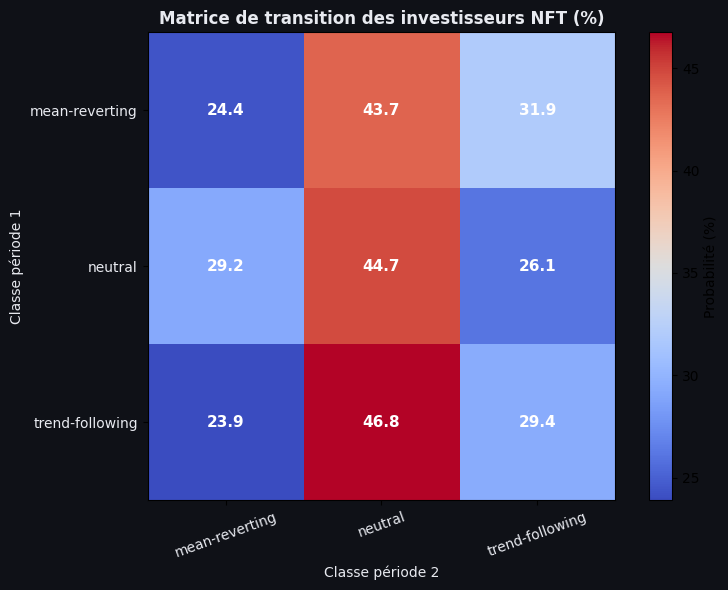

In [23]:
# ── Transition-matrix heatmap ───────────────────────
order = ["mean-reverting", "neutral", "trend-following"]
tm = transition_matrix.select(["type_period1"] + order)
labels_tm = tm["type_period1"].to_list()
values_tm = tm.select(order).to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)
im = ax.imshow(values_tm, cmap="coolwarm")
ax.set_xticks(np.arange(len(order))); ax.set_yticks(np.arange(len(order)))
ax.set_xticklabels(order, rotation=20, color=WHITE)
ax.set_yticklabels(order, color=WHITE)
ax.set_xlabel("Class in period 2", color=WHITE)
ax.set_ylabel("Class in period 1", color=WHITE)
ax.set_title("NFT investor transition matrix (%)", color=WHITE, fontsize=12, fontweight="bold")
for i in range(len(order)):
    for j in range(len(order)):
        ax.text(j, i, f"{values_tm[i,j]:.1f}", ha="center", va="center",
                color="white", fontsize=11, fontweight="bold")
fig.colorbar(im).set_label("Probability (%)", color='black')
plt.tight_layout()
plt.show()

### Results: stability

For the 2,287 wallets classified in both halves of the sample, **the three rows of the transition matrix are almost identical**: whatever the label in period 1, the label in period 2 is roughly 24–29% mean-reverting, 44–47% neutral and 26–32% trend-following. A wallet labelled mean-reverting in period 1 is even slightly *less* likely to be mean-reverting in period 2 (24.4%) than a wallet that was neutral (29.2%).

In other words, the period-2 label is statistically independent of the period-1 label. The directional labels are not persistent traits of wallets. That is compatible with agents switching strategies (Brock–Hommes-type models), but also with labels that mostly reflect noise.

---

## Section 7 — Optimal reaction horizons (T*)

### Approach

For each trader, we compute the correlation between their inventory change and the past price signal over different horizons $T$ from 1 to 50 days:

$$\text{corr}\bigl(\Delta\text{inv}_t,\; \log P_t - \log P_{t-T}\bigr)$$

The optimal horizon **T*** is the horizon that maximizes the absolute value of this correlation for each trader. The distribution of T* reveals the **diversity of memory horizons** in the market.

> **Mathematical context:** $\log P_t - \log P_{t-T}$ is the cumulative log return over the previous $T$ days. A positive correlation means the trader reacts in the same direction as past price moves; a negative correlation means they trade against past price moves.

In [24]:
# ── Past price signals ──────────────────────
T_MAX = 50

price_df = (
    df_sales
    .with_columns(pl.col("dt").dt.date().alias("date"))
    .group_by("date")
    .agg(pl.col("payment_usd_price").median().alias("price"))
    .sort("date")
    .with_columns(pl.col("price").log().alias("log_price"))
)

signals = price_df.select(["date", "log_price"])
for T in range(1, T_MAX + 1):
    signals = signals.with_columns(
        (pl.col("log_price") - pl.col("log_price").shift(T)).alias(f"signal_T{T}")
    )
signals = signals.drop_nulls()

data_merged = inventory_with_returns.join(signals, on="date", how="inner")
print(f"Merged dataset : {data_merged.shape}")

Merged dataset : (1987257, 57)


In [ ]:

# ── Correlation per trader and horizon T (Pearson + p-value) ─
results_corr = []
for T in range(1, T_MAX + 1):
    grouped = (
        data_merged
        .group_by("trader")
        .agg([
            pl.col(f"signal_T{T}"),
            pl.col("delta_inventory"),
            pl.len().alias("n_obs")
        ])
        .filter(pl.col("n_obs") >= 30)
    )
    records = []
    for row in grouped.iter_rows(named=True):
        sig = np.array(row[f"signal_T{T}"], dtype=float)
        di  = np.array(row["delta_inventory"], dtype=float)
        r, p = pearsonr(sig, di)
        records.append({"trader": row["trader"], "corr": r, "pvalue": p,
                        "n_obs": row["n_obs"], "T": T})
    results_corr.append(pl.DataFrame(records))

final_corr = pl.concat(results_corr)
print(f"Rows in final_corr : {len(final_corr):,}  (traders × horizons)")

Rows in final_corr : 472,200  (traders × horizons)


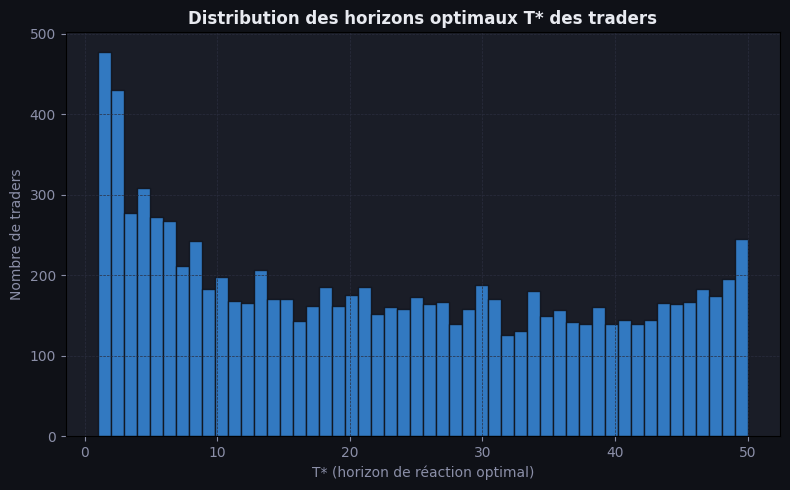

In [ ]:
# ── Optimal T* per trader (significant correlations only) ─
best_T = (
    final_corr
    .filter(pl.col("pvalue") < 0.05)            # keep significant correlations only
    .with_columns(pl.col("corr").abs().alias("abs_corr"))
    .sort(["trader", "abs_corr"], descending=True)
    .group_by("trader")
    .agg([
        pl.first("T").alias("T_best"),
        pl.first("corr").alias("best_corr"),
        pl.first("pvalue").alias("best_pvalue"),
    ])
)

print(f"Traders with at least one significant T : {best_T.height}")
T_vals = best_T["T_best"].to_list()

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)
ax.hist(T_vals, bins=50, color=BLUE, alpha=0.85, edgecolor=DARK)
ax.set_xlabel("T* (optimal reaction horizon)", color=LGRAY)
ax.set_ylabel("Number of traders", color=LGRAY)
ax.tick_params(colors=LGRAY)
ax.set_title("Distribution of optimal horizons T* (p < 0.05)", color=WHITE, fontsize=12, fontweight='bold')
ax.grid(True, color='#2a2d3e', linewidth=0.5, linestyle='--')
plt.tight_layout()
plt.show()

### Results: reaction horizons

T* is spread over the whole 1–50-day range with no dominant horizon, and the best correlations remain small (|r| < 0.2). Picking, for each wallet, the best of 50 correlated horizons is itself a multiple-testing procedure, so this histogram should be read as "no characteristic horizon" rather than as evidence of multi-scale strategies.

---

## Section 8 — Normalized PnL and trader informativeness

### Approach

For each trader and each horizon $T$, we compute the **directional PnL**:

$$\text{PnL}_{i,T} = \text{sign}(\Delta\text{inv}_{i,t}) \times r_{t \to t+T}$$

This gain measures whether the direction of the trader's inventory movement, buying or selling, correctly predicts the direction of the market over the next $T$ days. We normalize it using a **Sharpe ratio** so that traders can be compared independently of the volatility of their trading outcomes.

A **cross-sectional z-score** is then used to identify the most informative traders across all horizons.

> **Mathematical context:** the sign function keeps only the direction of the trade. A positive PnL means the trader's net position was aligned with the subsequent market move; a negative PnL means it was on the wrong side of the next move.

In [27]:
# ── Market volatility (normalisation reference) ─────────
market_vol = (
    inventory_with_returns
    .select(pl.col("return_prev").std().alias("sigma"))
    .item(0, 0)
)
print(f"Market volatility (std of log-returns) : {market_vol:.6f}")

# ── Forward returns ───────────────────────────
log_prices_fwd = price_df.select(["date", "log_price"])
for T in range(1, T_MAX + 1):
    log_prices_fwd = log_prices_fwd.with_columns(
        (pl.col("log_price").shift(-T) - pl.col("log_price")).alias(f"fwd_ret_T{T}")
    )
log_prices_fwd = log_prices_fwd.drop_nulls()

data_pnl = (
    inventory_with_returns
    .join(log_prices_fwd, on="date", how="inner")
    .with_columns(pl.col("delta_inventory").sign().alias("direction"))
)

Market volatility (std of log-returns) : 0.581337


In [28]:
# ── PnL per trader and horizon ───────────────────
pnl_results = []
for T in range(1, T_MAX + 1):
    ret_col = f"fwd_ret_T{T}"
    tmp = (
        data_pnl
        .with_columns((pl.col("direction") * pl.col(ret_col)).alias("trade_ret"))
        .group_by("trader")
        .agg([
            pl.col("trade_ret").mean().alias("pnl_raw"),
            pl.col("trade_ret").std().alias("pnl_std"),
            pl.len().alias("n_obs"),
        ])
        .filter(pl.col("n_obs") >= 30)
        .with_columns([
            pl.lit(T).alias("T"),
            (pl.col("pnl_raw") / (pl.col("pnl_std") + 1e-8)).alias("pnl_sharpe"),
        ])
    )
    pnl_results.append(tmp)

pnl_table = pl.concat(pnl_results)

# Cross-sectional z-score
sharpe_mean = pnl_table["pnl_sharpe"].mean()
sharpe_std  = pnl_table["pnl_sharpe"].std()
pnl_table = pnl_table.with_columns(
    ((pl.col("pnl_sharpe") - sharpe_mean) / (sharpe_std + 1e-8)).alias("pnl_zscore")
)

pnl_summary = (
    pnl_table
    .group_by("T")
    .agg([
        pl.col("pnl_raw").mean().alias("mean_pnl_raw"),
        pl.col("pnl_sharpe").mean().alias("mean_sharpe"),
        pl.col("pnl_sharpe").std().alias("std_sharpe"),
    ])
    .sort("T")
)

trader_scores = (
    pnl_table
    .group_by("trader")
    .agg([
        pl.col("pnl_zscore").mean().alias("avg_zscore"),
        pl.col("pnl_sharpe").mean().alias("avg_sharpe"),
        pl.col("pnl_raw").mean().alias("avg_pnl_raw"),
    ])
    .sort("avg_zscore", descending=True)
)

print("Top 10 traders (mean z-score) :")
print(trader_scores.head(10))

Top 10 traders (mean z-score) :
shape: (10, 4)
┌──────────────────┬────────────┬────────────┬─────────────┐
│ trader           ┆ avg_zscore ┆ avg_sharpe ┆ avg_pnl_raw │
│ ---              ┆ ---        ┆ ---        ┆ ---         │
│ str              ┆ f64        ┆ f64        ┆ f64         │
╞══════════════════╪════════════╪════════════╪═════════════╡
│ 6dfa96a7a623a4dd ┆ 3.889185   ┆ 0.96818    ┆ 0.397077    │
│ 4197b52fcf8a2aff ┆ 3.385656   ┆ 0.844772   ┆ 1.02002     │
│ 3d59be9bfc97f314 ┆ 3.361228   ┆ 0.838785   ┆ 0.934455    │
│ 5299c18bf8ae201b ┆ 3.128315   ┆ 0.781701   ┆ 0.804971    │
│ 027020c54428ba31 ┆ 3.035838   ┆ 0.759036   ┆ 0.937866    │
│ 80bcc38843ce33c1 ┆ 2.864672   ┆ 0.717086   ┆ 0.278081    │
│ 6d252299bd52f14f ┆ 2.830203   ┆ 0.708638   ┆ 0.581156    │
│ 0a42503bd689625d ┆ 2.82381    ┆ 0.707071   ┆ 0.81728     │
│ 390098c158f2b63a ┆ 2.764828   ┆ 0.692616   ┆ 0.474788    │
│ 0ed0227d0230ed41 ┆ 2.752578   ┆ 0.689613   ┆ 0.887841    │
└──────────────────┴────────────┴─────

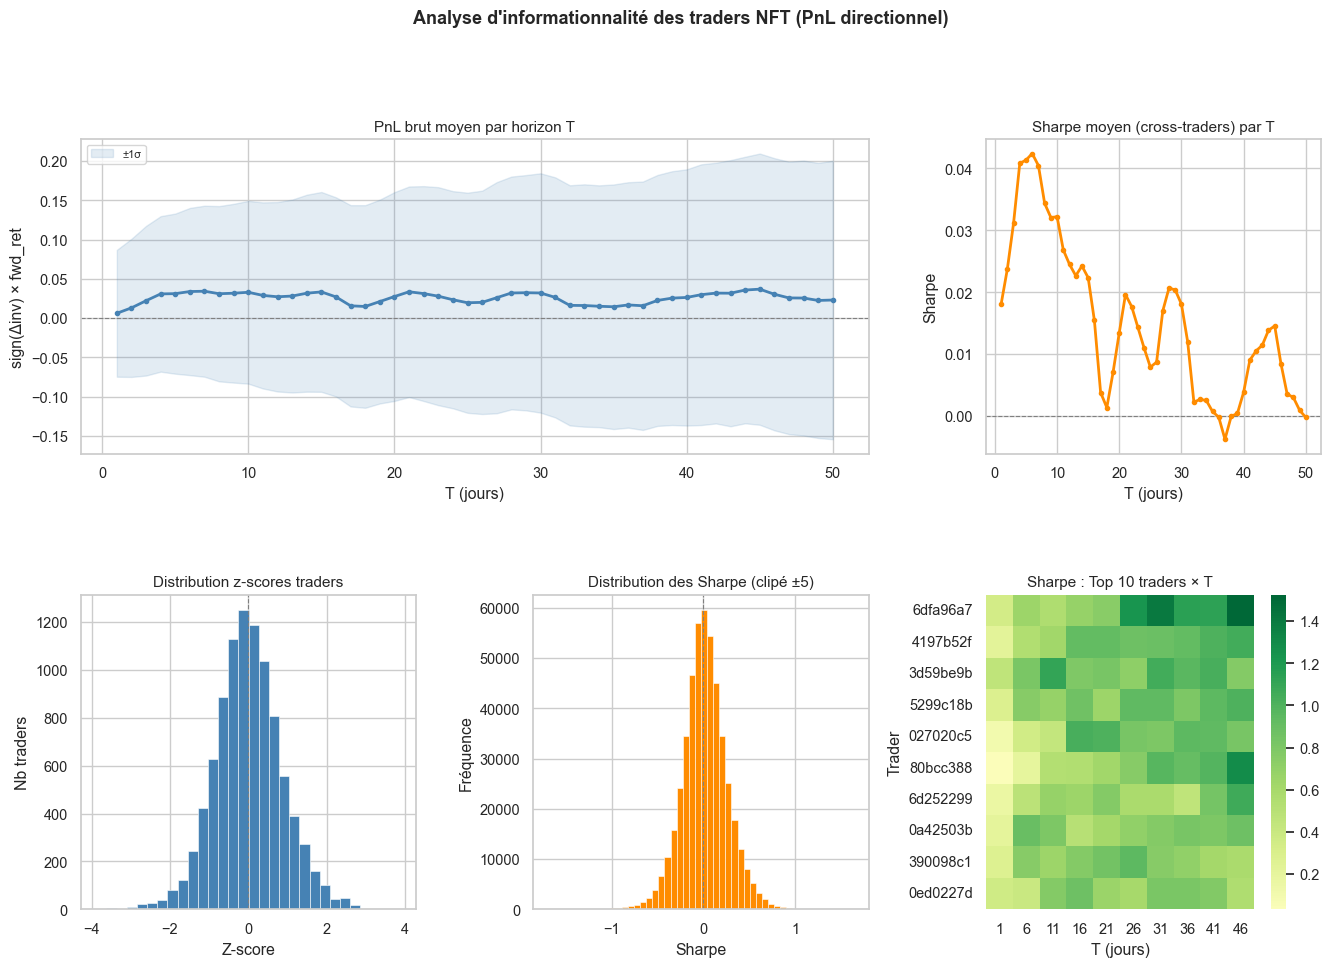

In [29]:
# ── PnL dashboard ───────────────────────────────────────
sns.set_theme(style="whitegrid", font_scale=0.95)

fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

T_arr        = pnl_summary["T"].to_numpy()
mean_raw_arr = pnl_summary["mean_pnl_raw"].to_numpy()
mean_sh_arr  = pnl_summary["mean_sharpe"].to_numpy()
std_sh_arr   = pnl_summary["std_sharpe"].to_numpy()
sharpes_all  = np.clip(pnl_table["pnl_sharpe"].to_numpy(), -5, 5)
avg_zscores  = trader_scores["avg_zscore"].to_numpy()

# Mean raw PnL ± 1σ by horizon
ax1 = fig.add_subplot(gs[0, :2])
ax1.axhline(0, color="grey", lw=0.8, ls="--")
ax1.fill_between(T_arr, mean_raw_arr - std_sh_arr*market_vol,
                 mean_raw_arr + std_sh_arr*market_vol,
                 alpha=0.15, color="steelblue", label="±1σ")
ax1.plot(T_arr, mean_raw_arr, color="steelblue", lw=2, marker="o", ms=3)
ax1.set_title("Mean raw PnL by horizon T", fontsize=11)
ax1.set_xlabel("T (days)"); ax1.set_ylabel("sign(Δinv) × fwd_ret")
ax1.legend(fontsize=8)

# Mean Sharpe by horizon
ax2 = fig.add_subplot(gs[0, 2])
ax2.axhline(0, color="grey", lw=0.8, ls="--")
ax2.plot(T_arr, mean_sh_arr, color="darkorange", lw=2, marker="o", ms=3)
ax2.set_title("Mean Sharpe (across traders) by T", fontsize=11)
ax2.set_xlabel("T (days)"); ax2.set_ylabel("Sharpe")

# Distribution of z-scores
ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(avg_zscores, bins=30, color="steelblue", edgecolor="white", lw=0.4)
ax3.axvline(0, color="grey", ls="--", lw=0.8)
ax3.set_title("Distribution of trader z-scores", fontsize=11)
ax3.set_xlabel("Z-score"); ax3.set_ylabel("Number of traders")

# Distribution of Sharpe ratios
ax4 = fig.add_subplot(gs[1, 1])
ax4.hist(sharpes_all, bins=50, color="darkorange", edgecolor="white", lw=0.4)
ax4.axvline(0, color="grey", ls="--", lw=0.8)
ax4.set_title("Distribution of Sharpe ratios (clipped ±5)", fontsize=11)
ax4.set_xlabel("Sharpe"); ax4.set_ylabel("Frequency")

# Heatmap top 10 traders × T (subsampled T for readability)
ax5 = fig.add_subplot(gs[1, 2])
top10 = trader_scores.head(10)["trader"].to_list()
T_sample = list(range(1, T_MAX+1, 5))
heat = []
for trader in top10:
    row = []
    for T in T_sample:
        filt = pnl_table.filter((pl.col("trader")==trader) & (pl.col("T")==T))
        row.append(filt["pnl_sharpe"].item(0) if filt.height > 0 else np.nan)
    heat.append(row)
sns.heatmap(np.array(heat), ax=ax5, cmap="RdYlGn", center=0,
            xticklabels=T_sample, yticklabels=[t[:8] for t in top10], linewidths=0)
ax5.set_title("Sharpe : Top 10 traders × T", fontsize=11)
ax5.set_xlabel("T (days)"); ax5.set_ylabel("Trader")

plt.suptitle("Informativeness of NFT traders (directional PnL)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Reading the upper charts

The upper charts should be interpreted as measures of **directional information** rather than raw profitability. A trader can appear informative when their net buying tends to be followed by positive returns, or when their net selling tends to be followed by negative returns.

If the average curve is close to zero, the aggregate signal is weak: traders' inventory changes do not systematically anticipate future market moves. Peaks at specific horizons indicate the time scale at which trader flows contain the most information, but small peaks should be interpreted cautiously because they may reflect noise rather than stable predictive skill.

The comparison across horizons is therefore essential: a genuinely informative trader should display a relatively stable positive signal across neighboring horizons, not just an isolated spike.

---

## Section 9 — Performance persistence

### Central question

> *“Do good traders remain good? Do bad traders remain bad?”*

### Approach

We split the sample into two equal periods (50/50) and compute each trader's average gain separately in each period. We then measure:
- the **Pearson/Spearman correlation** between performances in the two periods;
- the **quartile transition matrix**, for example whether a trader in Q4 in period 1 remains in Q4 in period 2;
- the **persistence of the top/bottom 20%**.

> **Mathematical context:** persistence is an out-of-sample stability test. If performance is skill-based, high performers in period 1 should remain more likely than chance to be high performers in period 2.

In [30]:
# ── 50/50 time split ──────────────────────────────────────
all_dates_uniq = data_pnl.select("date").unique().sort("date")
n_d = all_dates_uniq.height
split_idx = int(n_d * 0.5)

train_dates = all_dates_uniq.head(split_idx)["date"].to_list()
test_dates  = all_dates_uniq.tail(n_d - split_idx)["date"].to_list()

print(f"Period 1 : {train_dates[0]} → {train_dates[-1]}  ({len(train_dates)} days)")
print(f"Period 2 : {test_dates[0]}  → {test_dates[-1]}   ({len(test_dates)} days)")

T_test = [1, 5, 10, 20, 30, 50]
persist_results = []

for T in T_test:
    ret_col = f"fwd_ret_T{T}"
    def gains_for_period(dates):
        return (
            data_pnl.filter(pl.col("date").is_in(dates))
            .with_columns((pl.col("direction") * pl.col(ret_col)).alias("trade_ret"))
            .group_by("trader")
            .agg([
                pl.col("trade_ret").mean().alias("gain"),
                pl.len().alias("n_obs"),
            ])
            .filter(pl.col("n_obs") >= 30)
        )
    g1 = gains_for_period(train_dates).rename({"gain": "gain1", "n_obs": "n1"})
    g2 = gains_for_period(test_dates).rename({"gain": "gain2", "n_obs": "n2"})
    combined = g1.join(g2, on="trader", how="inner").with_columns(pl.lit(T).alias("T"))
    persist_results.append(combined)

all_persist = pl.concat(persist_results)

# Persistence metrics by T
metrics = []
for T in T_test:
    df_T = all_persist.filter(pl.col("T") == T)
    g1 = df_T["gain1"].to_numpy(); g2 = df_T["gain2"].to_numpy()
    n_top = max(1, int(len(g1)*0.2))
    top1 = set(np.argsort(-g1)[:n_top]); top2 = set(np.argsort(-g2)[:n_top])
    bot1 = set(np.argsort(g1)[:n_top]);  bot2 = set(np.argsort(g2)[:n_top])
    metrics.append({
        "T": T,
        "Pearson":  float(np.corrcoef(g1, g2)[0,1]),
        "Spearman": float(stats.spearmanr(g1, g2)[0]),
        "Top20_%":  len(top1 & top2) / n_top * 100,
        "Bot20_%":  len(bot1 & bot2) / n_top * 100,
        "N":        len(g1),
    })

metrics_df = pl.DataFrame(metrics)
print(metrics_df)

Period 1 : 2021-05-02 → 2023-04-06  (705 days)
Period 2 : 2023-04-07  → 2025-03-11   (705 days)
shape: (6, 6)
┌─────┬──────────┬──────────┬───────────┬───────────┬─────┐
│ T   ┆ Pearson  ┆ Spearman ┆ Top20_%   ┆ Bot20_%   ┆ N   │
│ --- ┆ ---      ┆ ---      ┆ ---       ┆ ---       ┆ --- │
│ i64 ┆ f64      ┆ f64      ┆ f64       ┆ f64       ┆ i64 │
╞═════╪══════════╪══════════╪═══════════╪═══════════╪═════╡
│ 1   ┆ 0.014871 ┆ 0.016937 ┆ 23.076923 ┆ 20.979021 ┆ 718 │
│ 5   ┆ 0.001829 ┆ -0.0084  ┆ 20.27972  ┆ 21.678322 ┆ 718 │
│ 10  ┆ 0.072169 ┆ 0.064071 ┆ 25.174825 ┆ 18.881119 ┆ 718 │
│ 20  ┆ 0.083032 ┆ 0.06656  ┆ 23.776224 ┆ 21.678322 ┆ 718 │
│ 30  ┆ 0.05946  ┆ 0.051404 ┆ 23.076923 ┆ 20.27972  ┆ 718 │
│ 50  ┆ 0.028419 ┆ 0.019963 ┆ 18.881119 ┆ 20.979021 ┆ 718 │
└─────┴──────────┴──────────┴───────────┴───────────┴─────┘


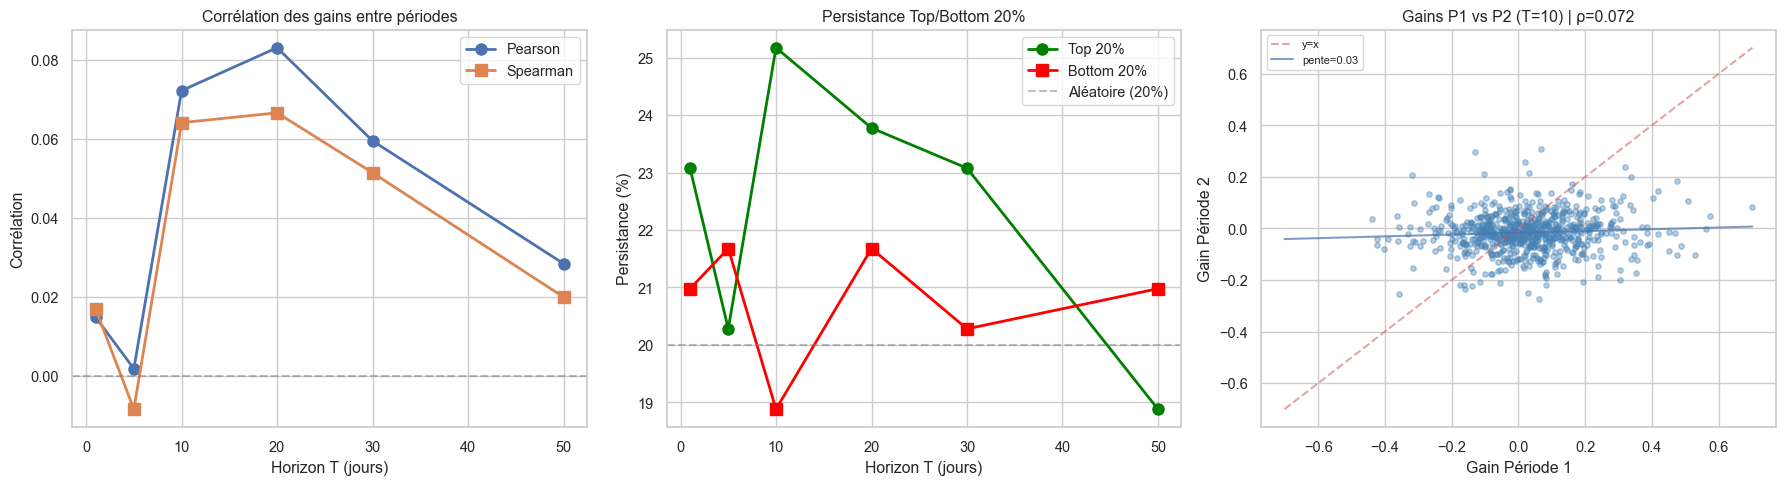

In [31]:
# ── Persistence plots ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid", font_scale=0.95)

T_arr_m = metrics_df["T"].to_numpy()

# Pearson and Spearman correlations by horizon
ax1 = axes[0]
ax1.plot(T_arr_m, metrics_df["Pearson"].to_numpy(), 'o-', label='Pearson', lw=2, ms=8)
ax1.plot(T_arr_m, metrics_df["Spearman"].to_numpy(), 's-', label='Spearman', lw=2, ms=8)
ax1.axhline(0, color='gray', ls='--', alpha=0.5)
ax1.set_xlabel("Horizon T (days)"); ax1.set_ylabel("Correlation")
ax1.set_title("Correlation of gains between periods"); ax1.legend()

# Top/bottom 20% persistence
ax2 = axes[1]
ax2.plot(T_arr_m, metrics_df["Top20_%"].to_numpy(), 'o-', color='green', lw=2, ms=8, label='Top 20%')
ax2.plot(T_arr_m, metrics_df["Bot20_%"].to_numpy(), 's-', color='red',   lw=2, ms=8, label='Bottom 20%')
ax2.axhline(20, color='gray', ls='--', alpha=0.5, label='Random (20%)')
ax2.set_xlabel("Horizon T (days)"); ax2.set_ylabel("Persistence (%)")
ax2.set_title("Top/Bottom 20% persistence"); ax2.legend()

# Scatter of gains P1 vs P2 for T=10
ax3 = axes[2]
T_ex = 10
df_ex = all_persist.filter(pl.col("T") == T_ex)
g1e, g2e = df_ex["gain1"].to_numpy(), df_ex["gain2"].to_numpy()
ax3.scatter(g1e, g2e, alpha=0.4, s=15, color='steelblue')
lim = max(abs(g1e).max(), abs(g2e).max())
ax3.plot([-lim, lim], [-lim, lim], 'r--', alpha=0.5, label='y=x')
z = np.polyfit(g1e, g2e, 1)
ax3.plot([-lim, lim], np.poly1d(z)([-lim, lim]), 'b-', alpha=0.7,
         label=f'slope={z[0]:.2f}')
rho = np.corrcoef(g1e, g2e)[0,1]
ax3.set_title(f"Gains P1 vs P2 (T={T_ex}) | ρ={rho:.3f}")
ax3.set_xlabel("Gain period 1"); ax3.set_ylabel("Gain period 2")
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Results: persistence

With 718 wallets present in both halves:
- the correlation between period-1 and period-2 gains ranges from 0.00 to 0.08 across horizons (standard error ≈ 0.037), so at most marginally positive at T = 10–20 days, and not robust across horizons;
- the share of top-quintile wallets that stay top-quintile is **19–25% against 20% for pure chance** (binomial standard error ≈ 3.3 points), and similarly for the bottom quintile.

**Past directional performance does not identify future winners.**

---

## Section 10 — Predicting returns from trader signals

### Approach

We test whether the **aggregate flows of traders** identified as “good” in the first period contain predictive information about future market returns.

**Protocol:**
1. In the **first half** of the sample (train), traders are classified as good or bad according to their Sharpe ratio at horizon T=10.
2. We compute **aggregate features**: the average directional signal of good traders, the average directional signal of bad traders, and their spread.
3. In the **second half** of the sample (test), we evaluate two predictive models: linear regression and Ridge regression.

This out-of-sample test measures whether trader information flows are **usable** for price prediction rather than only descriptive in-sample patterns.

> **Mathematical context:** Ridge regression adds an $L_2$ penalty to stabilize coefficients when predictors are noisy or correlated. This is useful here because aggregate trader signals may overlap strongly.

In [32]:
# ── Good/bad traders identified on the training period ─
CLASSIF_T = 10

train_data_cls = data_pnl.filter(pl.col("date").is_in(train_dates))

trader_perf = (
    train_data_cls
    .with_columns((pl.col("direction") * pl.col(f"fwd_ret_T{CLASSIF_T}")).alias("trade_ret"))
    .group_by("trader")
    .agg([
        pl.col("trade_ret").mean().alias("avg_gain"),
        pl.col("trade_ret").std().alias("std_gain"),
        pl.col("trade_ret").count().alias("n_obs"),
    ])
    .filter(pl.col("n_obs") >= 30)
    .with_columns((pl.col("avg_gain") / (pl.col("std_gain") + 1e-8)).alias("sharpe"))
)

n_top = max(1, int(trader_perf.height * 0.2))
good_traders = trader_perf.sort("sharpe", descending=True).head(n_top)["trader"].to_list()
bad_traders  = trader_perf.sort("sharpe", descending=False).head(n_top)["trader"].to_list()

print(f"Good traders (top 20%) : {len(good_traders)}")
print(f"Bad traders (bottom 20%) : {len(bad_traders)}")

Good traders (top 20%) : 1013
Bad traders (bottom 20%) : 1013


In [33]:
# ── Prediction features ───────────────────
def compute_signals(df_in, trader_list, name):
    return (
        df_in.filter(pl.col("trader").is_in(trader_list))
        .group_by("date")
        .agg([
            pl.col("direction").mean().alias(f"{name}_mean"),
            pl.col("direction").sum().alias(f"{name}_sum"),
            (pl.col("direction") * pl.col("return_prev")).mean().alias(f"{name}_momentum"),
        ])
    )

good_sig = compute_signals(data_pnl, good_traders, "good")
bad_sig  = compute_signals(data_pnl, bad_traders, "bad")
all_sig  = data_pnl.group_by("date").agg([
    pl.col("direction").mean().alias("all_mean"),
    pl.col("direction").sum().alias("all_sum"),
    (pl.col("direction") * pl.col("return_prev")).mean().alias("all_momentum"),
])

features_df = (
    all_sig
    .join(good_sig, on="date", how="left")
    .join(bad_sig, on="date", how="left")
    .fill_null(0)
    .with_columns((pl.col("good_mean") - pl.col("bad_mean")).alias("good_minus_bad"))
)

pred_data_full = features_df.join(log_prices_fwd, on="date", how="inner")
feature_cols = ["all_mean", "all_sum", "all_momentum",
                "good_mean", "good_sum", "good_momentum",
                "bad_mean", "bad_sum", "bad_momentum",
                "good_minus_bad"]

train_pred = pred_data_full.filter(pl.col("date").is_in(train_dates))
test_pred  = pred_data_full.filter(pl.col("date").is_in(test_dates))
print("Features built ✓")

Features built ✓


In [34]:
# ── Prediction models for several horizons ────────────
pred_horizons = [1, 5, 10, 20, 30]
pred_results  = []

for T in pred_horizons:
    target_col = f"fwd_ret_T{T}"
    X_tr = train_pred.select(feature_cols).to_numpy()
    y_tr = train_pred[target_col].to_numpy()
    X_te = test_pred.select(feature_cols).to_numpy()
    y_te = test_pred[target_col].to_numpy()

    valid_tr = ~(np.isnan(y_tr) | np.any(np.isnan(X_tr), axis=1))
    valid_te = ~(np.isnan(y_te) | np.any(np.isnan(X_te), axis=1))

    lr = LinearRegression().fit(X_tr[valid_tr], y_tr[valid_tr])
    ridge = Ridge(alpha=1.0).fit(X_tr[valid_tr], y_tr[valid_tr])

    pred_results.append({
        "T":          T,
        "LR_R2":      float(lr.score(X_te[valid_te], y_te[valid_te])),
        "LR_Corr":    float(np.corrcoef(y_te[valid_te], lr.predict(X_te[valid_te]))[0,1]),
        "Ridge_R2":   float(ridge.score(X_te[valid_te], y_te[valid_te])),
        "Ridge_Corr": float(np.corrcoef(y_te[valid_te], ridge.predict(X_te[valid_te]))[0,1]),
        "N_test":     int(valid_te.sum()),
    })

pred_df = pl.DataFrame(pred_results)
print(pred_df)

shape: (5, 6)
┌─────┬───────────┬───────────┬───────────┬────────────┬────────┐
│ T   ┆ LR_R2     ┆ LR_Corr   ┆ Ridge_R2  ┆ Ridge_Corr ┆ N_test │
│ --- ┆ ---       ┆ ---       ┆ ---       ┆ ---        ┆ ---    │
│ i64 ┆ f64       ┆ f64       ┆ f64       ┆ f64        ┆ i64    │
╞═════╪═══════════╪═══════════╪═══════════╪════════════╪════════╡
│ 1   ┆ -0.077864 ┆ -0.030795 ┆ -0.061365 ┆ -0.012132  ┆ 705    │
│ 5   ┆ -0.233268 ┆ -0.010302 ┆ -0.130405 ┆ 0.009979   ┆ 705    │
│ 10  ┆ -0.914951 ┆ -0.004448 ┆ -0.615736 ┆ 0.000315   ┆ 705    │
│ 20  ┆ -0.385967 ┆ -0.05074  ┆ -0.367389 ┆ -0.041776  ┆ 705    │
│ 30  ┆ -0.173717 ┆ 0.037196  ┆ -0.166481 ┆ 0.006178   ┆ 705    │
└─────┴───────────┴───────────┴───────────┴────────────┴────────┘


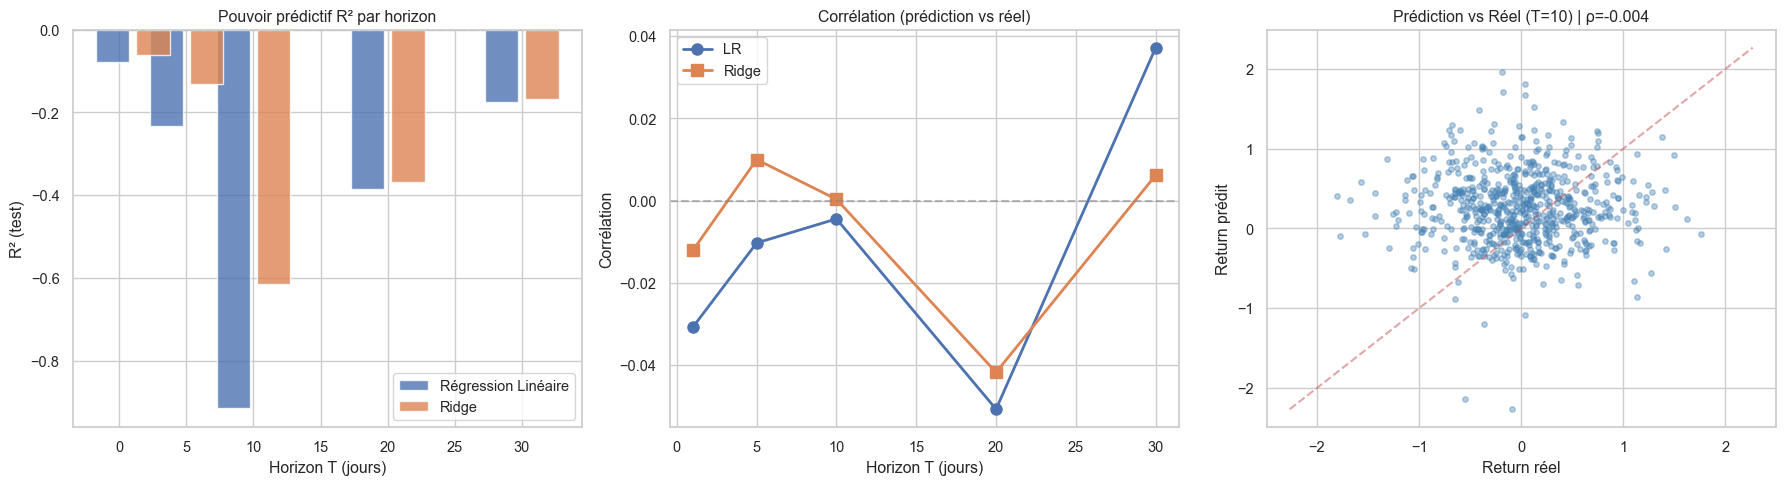

In [35]:
# ── Predictive performance plots ────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid", font_scale=0.95)

T_pa = pred_df["T"].to_numpy()

# R² by horizon
ax1 = axes[0]
ax1.bar(T_pa - 1.5, pred_df["LR_R2"].to_numpy(), width=2.5, label='Linear regression', alpha=0.8)
ax1.bar(T_pa + 1.5, pred_df["Ridge_R2"].to_numpy(), width=2.5, label='Ridge', alpha=0.8)
ax1.axhline(0, color='gray', ls='--', alpha=0.5)
ax1.set_xlabel("Horizon T (days)"); ax1.set_ylabel("R² (test)")
ax1.set_title("Out-of-sample R² by horizon"); ax1.legend()

# Correlation prediction vs realised
ax2 = axes[1]
ax2.plot(T_pa, pred_df["LR_Corr"].to_numpy(), 'o-', lw=2, ms=8, label='LR')
ax2.plot(T_pa, pred_df["Ridge_Corr"].to_numpy(), 's-', lw=2, ms=8, label='Ridge')
ax2.axhline(0, color='gray', ls='--', alpha=0.5)
ax2.set_xlabel("Horizon T (days)"); ax2.set_ylabel("Correlation")
ax2.set_title("Correlation (prediction vs realised)"); ax2.legend()

# Scatter prediction vs realised (T=10)
ax3 = axes[2]
T_ex = 10
X_te_ex = test_pred.select(feature_cols).to_numpy()
y_te_ex = test_pred[f"fwd_ret_T{T_ex}"].to_numpy()
valid_ex = ~(np.isnan(y_te_ex) | np.any(np.isnan(X_te_ex), axis=1))
lr10 = LinearRegression().fit(
    train_pred.select(feature_cols).to_numpy()[~np.isnan(train_pred[f"fwd_ret_T{T_ex}"].to_numpy())],
    train_pred[f"fwd_ret_T{T_ex}"].to_numpy()[~np.isnan(train_pred[f"fwd_ret_T{T_ex}"].to_numpy())]
)
y_pred_ex = lr10.predict(X_te_ex[valid_ex])
y_real_ex = y_te_ex[valid_ex]
ax3.scatter(y_real_ex, y_pred_ex, alpha=0.4, s=15, color='steelblue')
lim3 = max(abs(y_real_ex).max(), abs(y_pred_ex).max())
ax3.plot([-lim3, lim3], [-lim3, lim3], 'r--', alpha=0.5)
rho3 = np.corrcoef(y_real_ex, y_pred_ex)[0,1]
ax3.set_title(f"Prediction vs realised (T={T_ex}) | ρ={rho3:.3f}")
ax3.set_xlabel("Realised return"); ax3.set_ylabel("Predicted return")

plt.tight_layout()
plt.show()

### Results: prediction

The out-of-sample R² is **negative at every horizon** (OLS: from −0.08 at T = 1 to −0.91 at T = 10; ridge shrinks the damage but stays negative), and prediction/realisation correlations stay within about ±0.05. Ten features fitted on about 700 overlapping daily observations overfit the training half; the flows of "good" traders add nothing over the market-wide flow.

## Conclusions

| # | Question | Answer |
|---|---|---|
| 1 | Is activity per token a power law? | Heavy-tailed, but power law and log-normal are statistically tied |
| 2 | Is activity per wallet heavy-tailed? | Yes: α ≈ 2.2 for purchases and sales, exponential rejected, log-normal not |
| 3 | Is the most traded NFT special? | Its daily activity is thin-tailed (power law rejected, p < 0.001) |
| 5 | Can wallets be classified? | In-sample: 52% neutral, 24% trend-following, 23% mean-reverting |
| 6 | Are the labels stable? | **No**: period-2 labels are independent of period-1 labels |
| 7 | Is there a typical reaction horizon? | No characteristic horizon between 1 and 50 days |
| 9 | Does performance persist? | **No**: top-quintile persistence 19–25% vs 20% by chance |
| 10 | Do flows predict returns? | **No**: negative out-of-sample R² at all horizons |

### Limitations

- **The "market price" is the median USD price of all sales of the day.** It mixes collections whose prices differ by orders of magnitude, so its daily log-changes (std ≈ 0.58, i.e. 58% per day) are dominated by changes in the *composition* of what trades, not by price moves. A collection-level floor-price index or a repeat-sales index would be a much better market factor, and is the first thing I would change.
- **Composition noise can create mechanical correlations.** Large, noisy and mean-reverting index moves interact with wallets whose own trades enter the median. Part of the 48% "significant" classifications may come from this rather than from behaviour, which is consistent with the absence of persistence.
- **Multiple testing.** ~9,600 wallet-level tests at 5% and a best-of-50 horizon search per wallet; no False Discovery Rate correction (e.g. Benjamini–Hochberg) was applied.
- **Overlapping horizons.** Forward returns over T days overlap for consecutive days, which inflates apparent significance; HAC standard errors or non-overlapping samples would be needed for formal tests.
- **Data issues.** Grouping on `nft_identifier` alone (Section 1) and the 92,873 unparsed timestamps (Section 4), both noted above.
- A 10-minute-window variant of the classification was also explored by the team. It is not reproduced here because it relied on `nft_updated_at` (the metadata update time, not the trade time) and allowed wallets with only 3 observations.